In [1]:
from pathlib import Path
import hashlib, json, re
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, Delaunay
import plotly.graph_objects as go
from plotly.subplots import make_subplots

SHELL_PATH = Path(r"Nyl23114_aligned_bfactor_mapped_shell.pdb")  # set nylon shell file Path(r"NYL_newVer_rotY90resnum_bfactor_mapped_shell (2).pdb")
PIXEL_SIZE_A = 0.25
POINT_RADIUS_A = 0.75
OUTPUT_PATH = Path(f"Nylon_flat_face_projection_new/maps.npz")


In [10]:
def read_shell(path):
    lines = Path(path).read_text().splitlines()
    if sum(line.startswith("MODEL ") for line in lines) > 1:
        raise ValueError("Use a single-model shell PDB.")
    xyz, charge = [], []
    for number, line in enumerate(lines, 1):
        # if line[:6].strip() not in {"ATOM", "HETATM"}:
        #     continue
        if not line.startswith(("ATOM ", "HETATM")):
            continue
        try:
            xyz.append([float(line[a:b]) for a, b in ((30, 38), (38, 46), (46, 54))])
            token = re.match(r"\s*([-+]?(?:\d+(?:\.\d*)?|\.\d+))", line[60:])
            charge.append(float(token.group(1)))
        except (ValueError, AttributeError) as exc:
            raise ValueError(f"Invalid XYZ or B-factor charge at PDB line {number}.") from exc
    xyz, charge = np.asarray(xyz, float), np.asarray(charge, float)
    if xyz.ndim != 2 or xyz.shape[1] != 3 or len(xyz) < 4:
        raise ValueError("The shell must contain at least four 3D points.")
    if not np.isfinite(xyz).all() or not np.isfinite(charge).all():
        raise ValueError("Coordinates and charges must be finite.")
    return xyz, charge


def build_frame(xyz, centre):
    normal = np.array([-1., 0., 0.])
    u_axis, v_axis = np.array([0., -1., 0.]), np.array([0., 0., 1.])
    height = (xyz - centre) @ normal
    support = float(height.max())
    origin = centre + support * normal
    uv = (xyz - origin) @ np.stack([u_axis, v_axis], axis=1)
    return origin, normal, u_axis, v_axis, uv, support - height


def rasterize(uv, depth, charge, point_ids, u, v, radius):
    shape = (len(v), len(u))
    dmap, qmap = np.full(shape, np.inf), np.full(shape, np.nan)
    source = np.full(shape, -1, dtype=np.int64)
    count = np.zeros(shape, dtype=np.int32)
    step = u[1] - u[0]
    for pid in point_ids:
        up, vp = uv[pid]
        left = max(0, int(np.ceil((up - radius - u[0]) / step - 1e-9)))
        right = min(shape[1] - 1, int(np.floor((up + radius - u[0]) / step + 1e-9)))
        bottom = max(0, int(np.ceil((vp - radius - v[0]) / step - 1e-9)))
        top = min(shape[0] - 1, int(np.floor((vp + radius - v[0]) / step + 1e-9)))
        if left > right or bottom > top:
            continue
        U, V = u[left:right + 1][None, :], v[bottom:top + 1][:, None]
        covered = (U - up)**2 + (V - vp)**2 <= radius**2 + 1e-10
        block = np.s_[bottom:top + 1, left:right + 1]
        count[block] += covered
        nearer = covered & (depth[pid] < dmap[block] - 1e-10)
        dmap[block][nearer] = depth[pid]
        qmap[block][nearer] = charge[pid]
        source[block][nearer] = pid
    return qmap, dmap, source, count


In [11]:
def project_shell_points(xyz):
    normals = np.array([
        [-1., 0., 0.], [1., 0., 0.],
        [-0.5106372010275039, -0.0165423056080986, 0.8596371333600624],
        [0.5106372010275039, 0.0165423056080986, -0.8596371333600624],
        [0., 0.9998148979820791, 0.0192397965977849],
        [0., -0.9998148979820791, -0.0192397965977849],
    ])
    normals /= np.linalg.norm(normals, axis=1)[:, None]
    distances = np.max(xyz @ normals.T, axis=0) - xyz @ normals.T
    labels = np.argmin(distances, axis=1).astype(np.int16)
    target = (labels == 0) & (distances[:, 1:].min(axis=1) - distances[:, 0] > 1e-6)
    if target.sum() < 3:
        raise ValueError("No usable target wall. Check the shell orientation.")

    origin, normal, ua, va, uv, depth = build_frame(xyz, np.array([15.68610322, 33.75987287, 20.48624713]))
    polygon = uv[target][ConvexHull(uv[target]).vertices]
    following = np.roll(polygon, -1, axis=0)
    cross = polygon[:, 0] * following[:, 1] - following[:, 0] * polygon[:, 1]
    centroid = ((polygon + following) * cross[:, None]).sum(0) / (3 * cross.sum())
    centre = origin + centroid[0] * ua + centroid[1] * va
    origin, normal, ua, va, uv, depth = build_frame(xyz, centre)
    return origin, normal, ua, va, uv, depth, labels, target


def project_nylon(xyz, charge, pixel_size_A, point_radius_A, projected_shell=None):
    if not np.isfinite([pixel_size_A, point_radius_A]).all() or min(pixel_size_A, point_radius_A) <= 0:
        raise ValueError("Pixel size and point radius must be finite and positive.")

    if projected_shell is None:
        projected_shell = project_shell_points(xyz)
    origin, normal, ua, va, uv, depth, labels, target = projected_shell
    ku, kv = np.ceil((np.max(np.abs(uv[target]), axis=0) + point_radius_A) / pixel_size_A).astype(int) + 1
    if (2 * int(ku) + 1) * (2 * int(kv) + 1) > 1_000_000:
        raise ValueError("Grid exceeds 1,000,000 pixels. Check units or increase pixel size.")
    u = np.arange(-ku, ku + 1, dtype=float) * pixel_size_A
    v = np.arange(-kv, kv + 1, dtype=float) * pixel_size_A

    diameter = float(np.linalg.norm(np.ptp(xyz, axis=0)))
    shell_centre = xyz.mean(axis=0)
    camera_base = shell_centre + (float(origin @ normal) - shell_centre @ normal) * normal
    camera = camera_base + 100. * diameter * normal
    rel = xyz - camera
    radii = np.linalg.norm(rel, axis=1)
    radius = float(radii.max() * 10_000.)
    cloud = np.vstack([rel * (2 * radius / radii[:, None] - 1), np.zeros((1, 3))])
    hull = ConvexHull((cloud - cloud.mean(0)) / np.maximum(np.ptp(cloud, axis=0), 1e-12))
    visible = np.zeros(len(xyz), bool)
    visible[hull.vertices[hull.vertices < len(xyz)]] = True

    # Nearest-depth disc wins. Wall filtering follows whole-shell rasterization.
    qmap, dmap, source, count = rasterize(uv, depth, charge, np.flatnonzero(visible), u, v, point_radius_A)
    occupied = source >= 0
    valid = occupied.copy()
    valid[occupied] &= target[source[occupied]]
    qmap[~valid], dmap[~valid], source[~valid] = np.nan, np.nan, -1
    if not valid.any() or np.min(dmap[valid]) < -1e-7:
        raise ValueError("No valid target pixels or invalid support-plane depths.")
    dmap[valid] = np.maximum(dmap[valid], 0.)
    pixel_labels = np.full(valid.shape, -1, np.int16)
    pixel_labels[valid] = labels[source[valid]]
    owned = np.bincount(source[valid], minlength=len(xyz))
    U, V = np.meshgrid(u, v)
    footprint = uv[target][ConvexHull(uv[target]).vertices]
    inside = Delaunay(footprint).find_simplex(np.c_[U.ravel(), V.ravel()], tol=1e-9).reshape(U.shape) >= 0

    metadata = {
        "format_version": 3,
        "pipeline_version": "nylon-minimal-1.0",
        "units": {"coordinates": "angstrom", "depth": "angstrom", "charge": "input mapped charge"},
        "array_convention": "map[row,column]; row follows increasing v; column follows increasing u; origin=lower for plotting",
        "contact_model": "Global outward support plane of the complete shell.",
        "settings": {"pixel_size_A": pixel_size_A, "point_radius_A": point_radius_A,
                     "charge_scale": 1., "method": "points", "point_visibility": "hpr",
                     "hpr_camera_distance_factor": 100., "hpr_radius_factor": 10_000., "padding_pixels": 1},
        "facet_audit": {
            "single_wall_verified": bool(np.all(pixel_labels[valid] == 0)),
            "full_operational_target_wall_selected": bool(np.all(target[labels == 0])),
            "selected_shell_points": int(target.sum()),
            "centering": "Area centroid of the complete operational target-wall convex footprint",
            "convex_footprint_coverage": float(np.sum(valid & inside) / inside.sum()),
        },
        "visibility": "Approximate HPR visibility on the full shell, then bounded-disc first hit, then target-wall filtering.",
        "charge_model": "Mapped surface descriptor; no averaging or charge rescaling.",
        "missing_values": "NaN outside observed target support; zero is a valid value.",
    }
    maps = dict(charge=qmap, charge_raw=qmap.copy(), depth_A=dmap, valid_mask=valid,
                roi_mask=np.ones(valid.shape, bool), u_A=u, v_A=v, source_point_id=source,
                source_face_id=np.full(valid.shape, -1, dtype=np.int64), candidate_count=count,
                plane_origin_A=origin, plane_normal=normal, u_axis=ua, v_axis=va,
                geometric_selection_mask=target, macro_wall_id=pixel_labels, shell_macro_wall_id=labels)
    return maps, metadata, target, owned


In [12]:
xyz, charge = read_shell(SHELL_PATH)
projected_shell = project_shell_points(xyz)
origin, normal, ua, va, uv, depth, labels, target = projected_shell
point_ids = np.flatnonzero(target)
point_data = np.column_stack([point_ids, charge[point_ids], depth[point_ids]])
points_fig = make_subplots(rows=1, cols=2, subplot_titles=("Charge", "Depth"), horizontal_spacing=.15)
panels = [
    (charge[point_ids], [[0, "red"], [.5, "white"], [1, "blue"]], -1, 1, "Mapped charge", .43),
    (depth[point_ids], "Viridis", 0, float(depth[point_ids].max()), "Depth (Å)", 1.02),
]
for col, (values, palette, vmin, vmax, label, bar_x) in enumerate(panels, 1):
    points_fig.add_trace(go.Scattergl(
        x=uv[point_ids, 0], y=uv[point_ids, 1], mode="markers", showlegend=False,
        marker=dict(size=3, color=values, colorscale=palette, cmin=vmin, cmax=vmax,
                    colorbar=dict(title=label, x=bar_x, thickness=12, len=.8)),
        customdata=point_data,
        hovertemplate="Point %{customdata[0]:.0f}<br>u: %{x:.3f} Å<br>v: %{y:.3f} Å<br>Charge: %{customdata[1]:.3f}<br>Depth: %{customdata[2]:.3f} Å<extra></extra>",
    ), row=1, col=col)
    points_fig.update_xaxes(title_text="u (Å)", row=1, col=col)
    points_fig.update_yaxes(title_text="v (Å)", scaleanchor="x" if col == 1 else "x2",
                           scaleratio=1, row=1, col=col)
points_fig.update_layout(title="Nylon: raw projected shell points (before HPR and rasterization)",
                         template="plotly_white", height=650, margin=dict(l=50, r=70, b=50, t=90))
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
POINTS_HTML_PATH = OUTPUT_PATH.with_name("nylon_shell_points.html")
points_fig.write_html(POINTS_HTML_PATH, include_plotlyjs=True, full_html=True, auto_open=False,
                      config={"displaylogo": False})
print(f"Saved: {POINTS_HTML_PATH.resolve()} | {len(point_ids):,} raw target-wall points")
points_fig.show(renderer="vscode")


Saved: C:\Users\pklyt\Desktop\studia\DOKTORAT\SOLENZ\testing_projection\Nylon_flat_face_projection_new\nylon_shell_points.html | 77,785 raw target-wall points


In [13]:
maps, metadata, target, owned = project_nylon(xyz, charge, PIXEL_SIZE_A, POINT_RADIUS_A, projected_shell=projected_shell)
metadata.update(input_path=str(SHELL_PATH.resolve()),
                input_sha256=hashlib.sha256(SHELL_PATH.read_bytes()).hexdigest())
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(OUTPUT_PATH, **maps, metadata_json=json.dumps(metadata, allow_nan=False))
print(f"Shell: {len(xyz):,} points | target wall: {target.sum():,} | contributing: {(owned > 0).sum():,}")
print(f"Grid: {maps['charge'].shape} | valid pixels: {maps['valid_mask'].sum():,}")
print(f"Saved: {OUTPUT_PATH.resolve()}")


Shell: 165,835 points | target wall: 77,785 | contributing: 56,896
Grid: (877, 771) | valid pixels: 635,296
Saved: C:\Users\pklyt\Desktop\studia\DOKTORAT\SOLENZ\testing_projection\Nylon_flat_face_projection_new\maps.npz


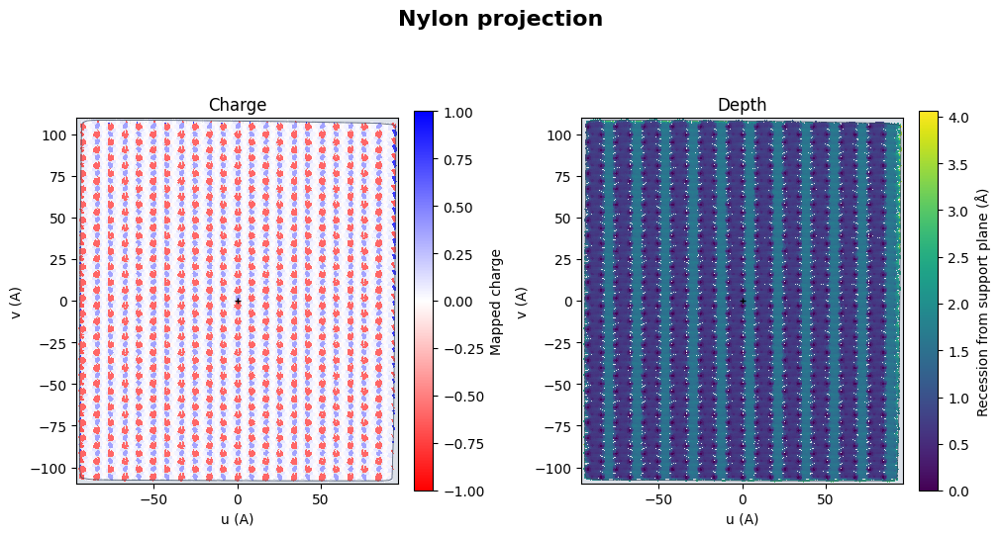

In [14]:
u, v = maps["u_A"], maps["v_A"]
h = u[1] - u[0]
extent = (u[0] - h/2, u[-1] + h/2, v[0] - h/2, v[-1] + h/2)
uv = (xyz - maps["plane_origin_A"]) @ np.stack([maps["u_axis"], maps["v_axis"]], axis=1)
wall_uv = uv[maps["geometric_selection_mask"]]
hull = wall_uv[ConvexHull(wall_uv).vertices]
hull = np.vstack([hull, hull[0]])

fig, axes = plt.subplots(1, 2, figsize=(10, 5.7), constrained_layout=True)
panels = [
    ("charge", "Charge", "bwr_r", -1, 1, "Mapped charge"),
    ("depth_A", "Depth", "viridis", 0, float(np.nanmax(maps["depth_A"])), "Recession from support plane (Å)"),
]
for ax, (key, title, palette, vmin, vmax, label) in zip(axes, panels):
    cmap = plt.get_cmap(palette).copy()
    cmap.set_bad("#dce1e8")
    im = ax.imshow(maps[key], origin="lower", extent=extent, interpolation="nearest",
                   cmap=cmap, vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=ax, shrink=.72, label=label)
    ax.plot(hull[:, 0], hull[:, 1], color="#34465b", lw=.65, alpha=.8)
    ax.plot(0, 0, "+", color="black", ms=5)
    ax.set(title=title, xlabel="u (A)", ylabel="v (A)", aspect="equal")
fig.suptitle("Nylon projection", fontsize=16, fontweight="bold")
plt.show()
plt.close(fig)


In [15]:
fig = go.Figure()
groups = [
    (~target, "Other shell points", "#b3bdc9", 1.3, 0.15),
    (target & (owned == 0), "Target wall: no assigned pixels", "#e49a32", 2., 0.8),
    (owned > 0, "Target wall: contributing points", "#15856d", 2., 1.),
]
for mask, name, colour, size, opacity in groups:
    ids = np.flatnonzero(mask)
    fig.add_trace(go.Scatter3d(
        x=xyz[ids, 0], y=xyz[ids, 1], z=xyz[ids, 2], mode="markers", name=name,
        marker=dict(color=colour, size=size, opacity=opacity),
        customdata=np.column_stack([ids, charge[ids], owned[ids]]),
        hovertemplate="Point %{customdata[0]:.0f}<br>Charge %{customdata[1]:.3f}<br>Assigned pixels %{customdata[2]:.0f}<extra>%{fullData.name}</extra>",
    ))
fig.update_layout(
    title="Nylon shell and projected surface points", template="plotly_white", height=650,
    scene=dict(aspectmode="data", xaxis_title="X (A)", yaxis_title="Y (A)", zaxis_title="Z (A)",
               camera=dict(eye=dict(x=-1.6, y=-1.2, z=0.8))),
    legend=dict(orientation="h", y=-0.05), margin=dict(l=0, r=0, b=50, t=50),
)
fig.show(renderer="vscode")


In [16]:
html_fig = go.Figure(go.Surface(
    x=maps["u_A"], y=maps["v_A"],
    z=np.where(maps["valid_mask"], -maps["depth_A"], np.nan),
    surfacecolor=maps["charge"],
    colorscale=[[0, "red"], [0.5, "white"], [1, "blue"]], cmin=-1, cmax=1,
    connectgaps=False, colorbar=dict(title="Mapped charge"),
    lighting=dict(ambient=1, diffuse=0, specular=0, fresnel=0),
    customdata=np.dstack([maps["charge"], maps["depth_A"]]),
    hovertemplate="u: %{x:.2f} Å<br>v: %{y:.2f} Å<br>Charge: %{customdata[0]:.3f}<br>Depth: %{customdata[1]:.3f} Å<extra></extra>",
))
html_fig.update_layout(
    title="Nylon frontal face: plane projection", template="plotly_white",
    scene=dict(
        xaxis_title="u (A)", yaxis_title="v (A)", zaxis_title="-Depth (A)",
        aspectmode="data", bgcolor="#dce1e8",
        camera=dict(eye=dict(x=0, y=0, z=2.5), up=dict(x=0, y=1, z=0),
                    projection=dict(type="orthographic")),
    ),
    margin=dict(l=0, r=0, b=0, t=50),
)
HTML_PATH = OUTPUT_PATH.with_name("nylon_frontal_face.html")
html_fig.write_html(HTML_PATH, include_plotlyjs=True, full_html=True, auto_open=False,
                    config={"displaylogo": False})
print(f"Saved: {HTML_PATH.resolve()}")


Saved: C:\Users\pklyt\Desktop\studia\DOKTORAT\SOLENZ\testing_projection\Nylon_flat_face_projection_new\nylon_frontal_face.html
